In [1]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import geopandas as gpd

In [3]:
#pd---pandas
#gpd--Geopandas

In [4]:
import pandas as pd
df=pd.read_csv("Day7.csv")
df.head

<bound method NDFrame.head of     station_id        date station_name region  latitude  longitude  \
0         ST01  2026-06-01        Delhi  North     28.61      77.21   
1         ST02  2026-06-01   Chandigarh  North     30.73      76.78   
2         ST03  2026-06-01      Lucknow  North     26.85      80.95   
3         ST04  2026-06-01       Mumbai   West     19.07      72.87   
4         ST05  2026-06-01    Ahmedabad   West     23.02      72.57   
..         ...         ...          ...    ...       ...        ...   
115       ST08  2026-06-10      Chennai  South     13.08      80.27   
116       ST09  2026-06-10    Hyderabad  South     17.39      78.49   
117       ST10  2026-06-10  Bhubaneswar   East     20.30      85.82   
118       ST11  2026-06-10      Kolkata   East     22.57      88.36   
119       ST12  2026-06-10     Guwahati   East     26.14      91.74   

     temperature  rainfall  humidity   ndvi  elevation  
0           35.5      19.4      57.6  0.395        216  
1  

In [5]:
df.shape

(120, 11)

In [6]:
gdf=gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    )
)

In [7]:
gdf.head()

,station_id,date,station_name,region,latitude,longitude,temperature,rainfall,humidity,ndvi,elevation,geometry
0,ST01,2026-06-01,Delhi,North,28.61,77.21,35.5,19.4,57.6,0.395,216,POINT (77.21 28.61)
1,ST02,2026-06-01,Chandigarh,North,30.73,76.78,34.8,18.5,61.3,0.377,321,POINT (76.78 30.73)
2,ST03,2026-06-01,Lucknow,North,26.85,80.95,34.5,25.5,53.1,0.361,123,POINT (80.95 26.85)
3,ST04,2026-06-01,Mumbai,West,19.07,72.87,33.7,0.0,53.1,0.271,14,POINT (72.87 19.07)
4,ST05,2026-06-01,Ahmedabad,West,23.02,72.57,32.5,19.5,56.4,0.294,53,POINT (72.57 23.02)


In [8]:
gdf.geometry

0      POINT (77.21 28.61)
1      POINT (76.78 30.73)
2      POINT (80.95 26.85)
3      POINT (72.87 19.07)
4      POINT (72.57 23.02)
              ...         
115    POINT (80.27 13.08)
116    POINT (78.49 17.39)
117     POINT (85.82 20.3)
118    POINT (88.36 22.57)
119    POINT (91.74 26.14)
Name: geometry, Length: 120, dtype: geometry

In [9]:
gdf.geometry.geom_type

0      Point
1      Point
2      Point
3      Point
4      Point
       ...  
115    Point
116    Point
117    Point
118    Point
119    Point
Length: 120, dtype: str

In [10]:
gdf=gdf.set_crs("EPSG:4326")

In [11]:
gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [12]:
gdf_projected=gdf.to_crs

<Axes: >

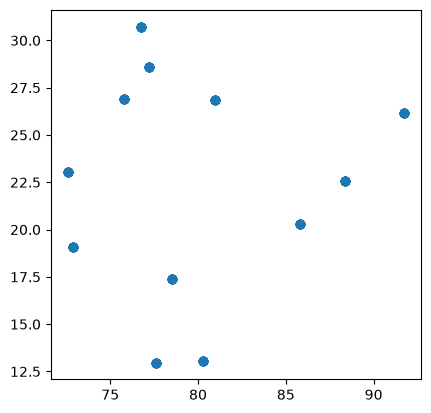

In [13]:
gdf.plot()

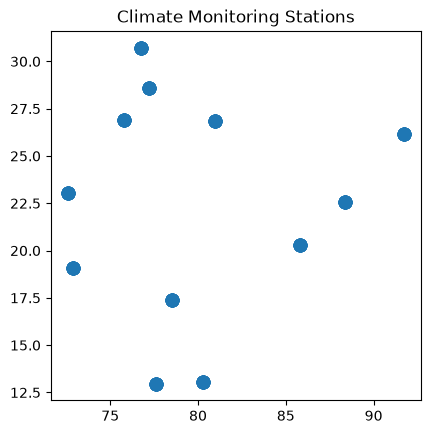

In [14]:
import matplotlib.pyplot as plt
gdf.plot(
    markersize=80
)
plt.title("Climate Monitoring Stations")
plt.show()

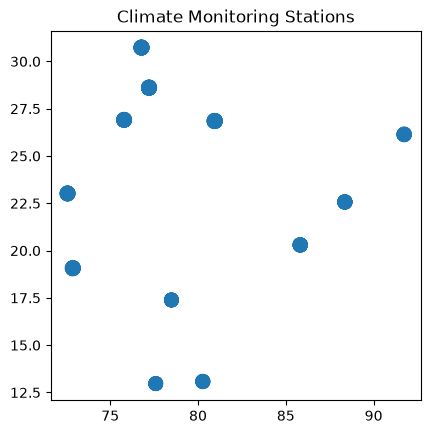

In [15]:
gdf.plot(
    markersize=gdf["temperature"]*3
)
plt.title("Climate Monitoring Stations")
plt.show()

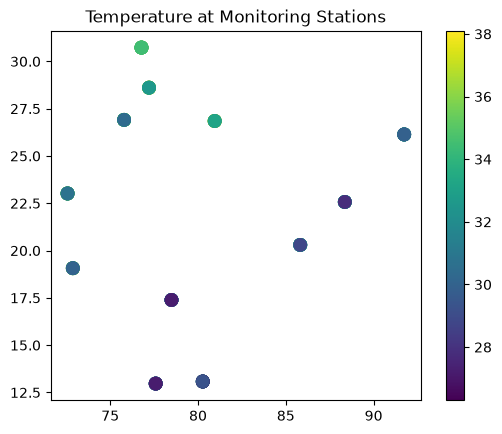

In [16]:
gdf.plot(
    column="temperature",
    legend=True,
    markersize=80
)
plt.title("Temperature at Monitoring Stations")
plt.show()

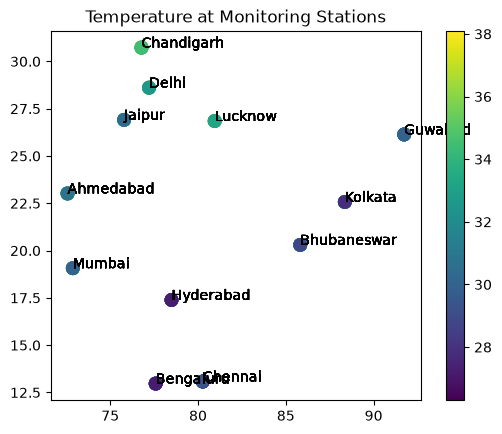

In [17]:
ax=gdf.plot(
    column="temperature",
    legend=True,
    markersize=80
)

for x,y, label in zip(
    gdf.geometry.x,
    gdf.geometry.y,
    gdf["station_name"]
):

    ax.text(x,y,label)

plt.title("Temperature at Monitoring Stations")
plt.show()

In [ ]:
# python+GIS+Remote Sensing+Machine Learning+ AI